# Deep Neural Networks with nn.MaduleList()

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as f
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from torch.utils.data import DataLoader,Dataset
torch.manual_seed(1)

In [2]:
# Define the function to plot the diagram

def plot_decision_regions_3class(model, data_set):
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#00AAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#00AAFF'])
    X = data_set.x.numpy()
    y = data_set.y.numpy()
    h = .02
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1 
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1 
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    XX = torch.Tensor(np.c_[xx.ravel(), yy.ravel()])
    _, yhat = torch.max(model(XX), 1)
    yhat = yhat.numpy().reshape(xx.shape)
    plt.pcolormesh(xx, yy, yhat, cmap=cmap_light)
    plt.plot(X[y[:] == 0, 0], X[y[:] == 0, 1], 'ro', label = 'y=0')
    plt.plot(X[y[:] == 1, 0], X[y[:] == 1, 1], 'go', label = 'y=1')
    plt.plot(X[y[:] == 2, 0], X[y[:] == 2, 1], 'o', label = 'y=2')
    plt.title("decision region")
    plt.legend()

### Create Dataset

In [3]:
# create Data class

class Data(Dataset):
        
    # Constructor
    def __init__(self, K=3, N=500):
        D = 2
        X = np.zeros((N * K, D)) # data matrix (each row = single example)
        y = np.zeros(N * K, dtype='uint8') # class labels
        for j in range(K):
          ix = range(N * j, N * (j + 1))
          r = np.linspace(0.0, 1, N) # radius
          t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2 # theta
          X[ix] = np.c_[r * np.sin(t), r*np.cos(t)]
          y[ix] = j
        self.y = torch.from_numpy(y).type(torch.LongTensor)
        self.x = torch.from_numpy(X).type(torch.FloatTensor)
        self.len = y.shape[0]
    
    # Getter
    def __getitem__(self, index):    
        return self.x[index], self.y[index]
    
    # Get Length
    def __len__(self):
        return self.len
    
    # Plot the diagram
    def plot_stuff(self):
        plt.plot(self.x[self.y[:] == 0, 0].numpy(), self.x[self.y[:] == 0, 1].numpy(), 'o', label="y = 0")
        plt.plot(self.x[self.y[:] == 1, 0].numpy(), self.x[self.y[:] == 1, 1].numpy(), 'ro', label="y = 1")
        plt.plot(self.x[self.y[:] == 2, 0].numpy(), self.x[self.y[:] == 2, 1].numpy(), 'go', label="y = 2")
        plt.legend()

## Neural Network Module and Function for Training

In [9]:
# create the model class
class n_net(nn.Module):

    # Constructor
    def __init__(self, Layers):
        super(n_net, self).__init__()
        self.hidden = nn.ModuleList()
        for input_size, output_size in zip(Layers, Layers[1:]):
            self.hidden.append(nn.Linear(input_size,output_size))

    # Prediction
    def forward(self, act):
        leng = len(self.hidden)
        for (l,linear_trans) in zip(range(leng), self.hidden):
            if l < leng - 1:
                act = f.relu(linear_trans(act))
            else:
                act = linear_trans(act)
        return act

In [5]:
# Define the function for training the model

def train(data_set, model, criterion, train_loader, optimizer, epochs=100):
    LOSS = []
    ACC = []
    for epoch in range(epochs):
        for x, y in train_loader:
            optimizer.zero_grad()
            yhat = model(x)
            loss = criterion(yhat, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            LOSS.append(loss.item())
        ACC.append(accuracy(model, data_set))
    
    fig, ax1 = plt.subplots()
    color = 'tab:red'
    ax1.plot(LOSS, color = color)
    ax1.set_xlabel('Iteration', color = color)
    ax1.set_ylabel('total loss', color = color)
    ax1.tick_params(axis = 'y', color = color)
    
    ax2 = ax1.twinx()  
    color = 'tab:blue'
    ax2.set_ylabel('accuracy', color = color)  # we already handled the x-label with ax1
    ax2.plot(ACC, color = color)
    ax2.tick_params(axis = 'y', color = color)
    fig.tight_layout()  # otherwise the right y-label is slightly clipped
    
    plt.show()
    return LOSS

In [6]:
# The function to calculate the accuracy

def accuracy(model, data_set):
    _, yhat = torch.max(model(data_set.x), 1)
    return (yhat == data_set.y).numpy().mean()

## Train and Valid the Model

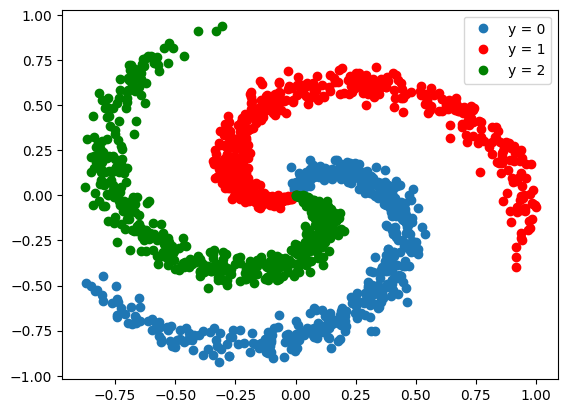

In [7]:
# create a Dataset object
dataset = Data()
dataset.plot_stuff()
dataset.y = dataset.y.view(-1)

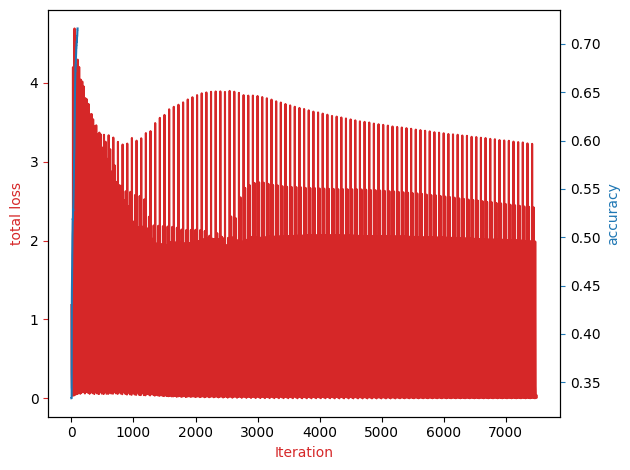

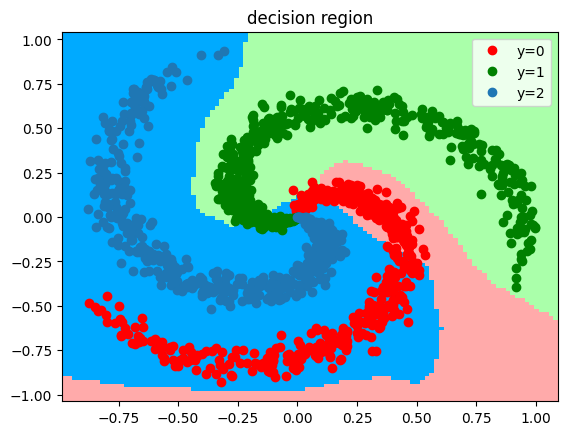

In [10]:
# train the model with 1 hidden layer with 50 neurons
Layers = [2,50,3]
model = n_net(Layers)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
train_loader = DataLoader(dataset=dataset, batch_size=20)
crt = nn.CrossEntropyLoss()
loss = train(dataset, model, crt, train_loader,opt, epochs=100)
plot_decision_regions_3class(model, dataset)

In [11]:
n_net([3,3,4,3]).parameters

<bound method Module.parameters of n_net(
  (hidden): ModuleList(
    (0): Linear(in_features=3, out_features=3, bias=True)
    (1): Linear(in_features=3, out_features=4, bias=True)
    (2): Linear(in_features=4, out_features=3, bias=True)
  )
)>

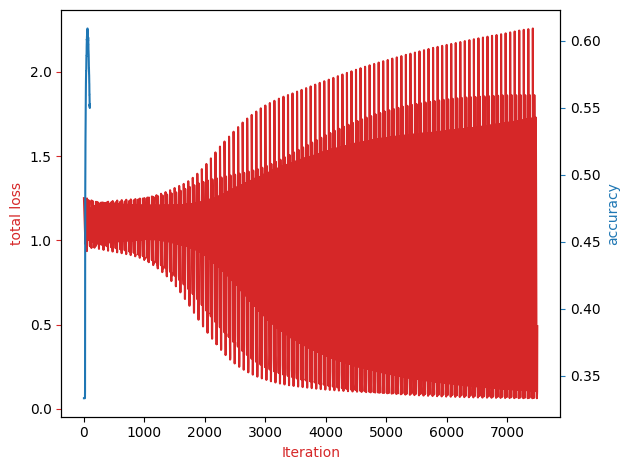

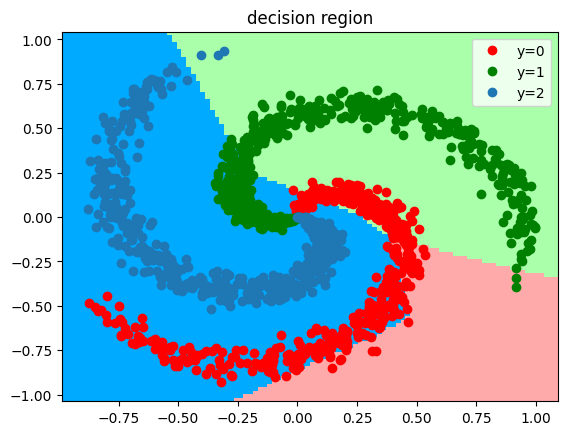

In [12]:
# train the model with 2 hidden layer with 20 neurons
Layers = [2,10,10,3]
model = n_net(Layers)
opt = torch.optim.SGD(model.parameters(), lr=0.01)
train_loader = DataLoader(dataset=dataset, batch_size=20)
crt = nn.CrossEntropyLoss()
loss = train(dataset, model, crt, train_loader,opt, epochs=100)
plot_decision_regions_3class(model, dataset)

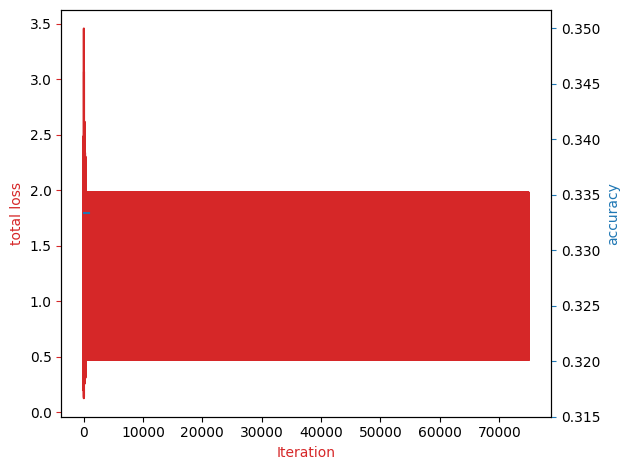

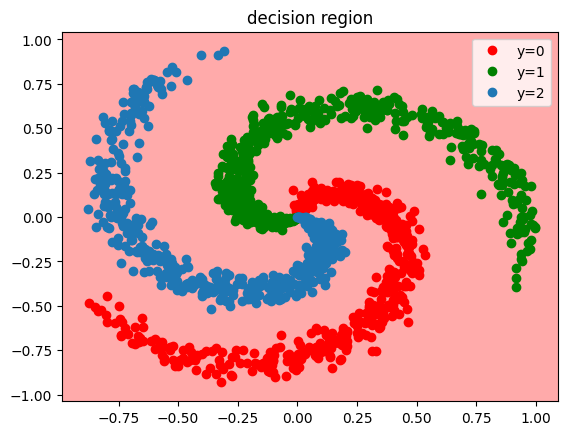

In [13]:
# train the model with 3 hidden layer with 10 neurons
Layers = [2,10,10,10,3]
model = n_net(Layers)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
train_loader = DataLoader(dataset=dataset, batch_size=20)
crt = nn.CrossEntropyLoss()
loss = train(dataset, model, crt, train_loader,opt, epochs=1000)
plot_decision_regions_3class(model, dataset)